# Train weather-only pre-typhoon profiles

Run these cells from top to bottom. No prefecture reconstruction, coordinates or LSTM is needed.

Train on the weather recorded **three, two and one day before confirmed landfall**. The original event labels are displayed as:

| Profile | Historical meaning |
|---|---|
| Low | Weather observed three days before landfall |
| Medium | Weather observed two days before landfall |
| High | Weather observed one day before landfall |

The model learns similarity to those event weather profiles. It cannot establish the chance of a typhoon occurring on an ordinary day because this dataset has no non-typhoon examples. Landfall-day rows are excluded. Dates and event identifiers are retained for evaluation and display, never used as model inputs.

## 1. Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "training":
    ROOT = ROOT.parent
elif (ROOT / "Typhoon" / "training").is_dir():
    ROOT = ROOT / "Typhoon"
TRAINING_DIR = ROOT / "training"
EXPERIMENT_ID = "weather_only_v1"
INPUT_FILE = ROOT / "data/processed/jma_day3_to_landfall_with_weather.csv"
OUTPUT_DIR = TRAINING_DIR / "trained_models/risk" / EXPERIMENT_ID
LOG_DIR = TRAINING_DIR / "experiment_logs/risk" / EXPERIMENT_ID

START_DATE = None  # None uses all available historical years
END_DATE = None
TEST_SIZE = 0.20
SEED = 42
REMOVE_FEATURES = []  # e.g. ["rain_sum"]
MODEL_PARAMS = {
    "Random Forest": {"n_estimators": 300, "max_depth": None},
    "CART": {"max_depth": None},
    "Gradient Boosting": {"n_estimators": 100, "learning_rate": 0.1},
    "SVM": {"C": 1.0, "kernel": "rbf"},
}
OVERWRITE_OUTPUTS = False

# Optional: CSV containing weather to classify (for example, predicted daily weather).
# Leave None to demonstrate prediction on a heldout row.
PREDICTION_FILE = None
MODEL_TO_VIEW = "Random Forest"
ROW_TO_VIEW = 0


## 2. Imports and checks

In [2]:
# Install once if needed:
# %pip install pandas numpy matplotlib scikit-learn joblib
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

assert 0 < TEST_SIZE < 1
if not INPUT_FILE.is_file():
    raise FileNotFoundError("Set INPUT_FILE to your existing historical weather/event CSV.")
for folder in [OUTPUT_DIR, LOG_DIR]:
    if folder.exists() and any(folder.iterdir()) and not OVERWRITE_OUTPUTS:
        raise FileExistsError(f"Choose a new EXPERIMENT_ID, or enable OVERWRITE_OUTPUTS: {folder}")


## 3. Load the three pre-landfall days

In [3]:
df = pd.read_csv(INPUT_FILE, encoding="utf-8-sig")
required = {"intl_id", "landfall_event_id", "date", "days_before_landfall"}
if not required.issubset(df.columns):
    raise ValueError(f"Historical input requires {sorted(required)}.")
if df[list(required)].isna().any().any():
    raise ValueError("Storm/event IDs, dates and day labels cannot be missing.")
df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()
df["days_before_landfall"] = pd.to_numeric(df.days_before_landfall, errors="raise")
df = df[df.days_before_landfall.isin([3, 2, 1])].copy()
if START_DATE is not None:
    df = df[df.date >= pd.Timestamp(START_DATE)]
if END_DATE is not None:
    df = df[df.date <= pd.Timestamp(END_DATE)]
df = df.sort_values(["date", "landfall_event_id"]).reset_index(drop=True)
if df.empty:
    raise ValueError("No pre-landfall rows in the selected period.")
if df.duplicated(["landfall_event_id", "date"]).any():
    raise ValueError("Duplicate event/date records must be resolved before training.")
if (df.groupby("landfall_event_id").intl_id.nunique() != 1).any():
    raise ValueError("Each event must belong to one storm.")
DAY_LABELS = {3: "Low", 2: "Medium", 1: "High"}
df["risk"] = df.days_before_landfall.map(DAY_LABELS)
print(f"{len(df)} pre-landfall rows | {df.intl_id.nunique()} storms | {df.landfall_event_id.nunique()} events")
print("Historical dates:", df.date.min().date(), "to", df.date.max().date())
display(df.risk.value_counts().reindex(["Low", "Medium", "High"]).rename("rows"))
display(df[["date", "landfall_event_id", "days_before_landfall", "risk"]].head())


588 pre-landfall rows | 102 storms | 200 events
Historical dates: 2000-09-09 to 2026-06-25


risk
Low       189
Medium    199
High      200
Name: rows, dtype: int64

,date,landfall_event_id,days_before_landfall,risk
0,2000-09-09,0014_2000091210,3,Low
1,2000-09-10,0014_2000091210,2,Medium
2,2000-09-11,0014_2000091210,1,High
3,2001-08-18,0111_2001082110,3,Low
4,2001-08-18,0111_2001082119,3,Low


## 4. Weather inputs only

In [4]:
WEATHER = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "dew_point_2m_max",
    "dew_point_2m_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "cloud_cover_mean",
    "cloud_cover_max",
    "cloud_cover_min",
    "pressure_msl_mean",
    "pressure_msl_max",
    "pressure_msl_min",
    "surface_pressure_mean",
    "surface_pressure_max",
    "surface_pressure_min",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "wind_speed_10m_min",
    "wind_gusts_10m_mean",
    "wind_gusts_10m_max",
    "wind_gusts_10m_min",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum"
]
unknown = set(REMOVE_FEATURES) - set(WEATHER)
if unknown:
    raise ValueError(f"Unknown weather names: {sorted(unknown)}")
FEATURES = [c for c in WEATHER if c not in REMOVE_FEATURES]
if not FEATURES:
    raise ValueError("Keep at least one weather feature.")
missing = set(FEATURES) - set(df.columns)
if missing:
    raise ValueError(f"Missing weather attributes: {sorted(missing)}")
for name in FEATURES:
    df[name] = pd.to_numeric(df[name], errors="raise")
if np.isinf(df[FEATURES].to_numpy()).any() or df[FEATURES].isna().all(axis=1).any():
    raise ValueError("Infinite inputs or rows with no weather observations.")
print("Raw weather inputs:", len(FEATURES))
display(pd.DataFrame({"weather_feature": FEATURES}))
print("Missing weather cells:", int(df[FEATURES].isna().sum().sum()))


Raw weather inputs: 29


,weather_feature
0,temperature_2m_mean
1,temperature_2m_max
2,temperature_2m_min
3,relative_humidity_2m_mean
4,relative_humidity_2m_max
5,relative_humidity_2m_min
6,dew_point_2m_mean
7,dew_point_2m_max
8,dew_point_2m_min
9,precipitation_sum


Missing weather cells: 0


## 5. Hold out whole typhoons
All rows and landfall events belonging to the same storm stay in one split. Preprocessing learns from training weather only.

In [5]:
groups = df.intl_id.astype(str)
if groups.nunique() < 4:
    raise ValueError("Need at least four independent storms for a useful holdout.")
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED).split(df, groups=groups))
train_df, test_df = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
assert set(train_df.intl_id).isdisjoint(test_df.intl_id)
assert set(train_df.landfall_event_id).isdisjoint(test_df.landfall_event_id)
if set(train_df.risk) != {"Low", "Medium", "High"}:
    raise ValueError("Training split must contain all three profiles.")
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df.risk, test_df.risk
if X_train.isna().all().any():
    raise ValueError("A training weather column has no observations; remove it or restore its values.")
print(f"Train: {len(train_df)} rows | Test: {len(test_df)} rows | Shared storms: 0")
display(pd.concat([y_train.value_counts().rename("train"), y_test.value_counts().rename("test")], axis=1).reindex(["Low", "Medium", "High"]).fillna(0))


Train: 479 rows | Test: 109 rows | Shared storms: 0


,train,test
risk,,
Low,154,35
Medium,162,37
High,163,37


## 6. Preprocessing and classification models
Weather variables are imputed and standardized. Wind direction is encoded as sine/cosine so 359° and 1° remain close. The saved model includes this preprocessing; prediction still takes the raw weather columns.

In [6]:
ANGLE = "wind_direction_10m_dominant"
NUMERIC = [c for c in FEATURES if c != ANGLE]
transformers = []
if NUMERIC:
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    transformers.append(("weather", numeric, NUMERIC))
if ANGLE in FEATURES:
    for name, function in [("direction_sin", np.sin), ("direction_cos", np.cos)]:
        circular = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("radians", FunctionTransformer(np.deg2rad)),
            ("angle", FunctionTransformer(function)),
        ])
        transformers.append((name, circular, [ANGLE]))
preprocessor = ColumnTransformer(transformers)
models = {
    "Random Forest": RandomForestClassifier(random_state=SEED, class_weight="balanced", n_jobs=2, **MODEL_PARAMS["Random Forest"]),
    "CART": DecisionTreeClassifier(random_state=SEED, class_weight="balanced", **MODEL_PARAMS["CART"]),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED, **MODEL_PARAMS["Gradient Boosting"]),
    "SVM": SVC(random_state=SEED, class_weight="balanced", probability=True, **MODEL_PARAMS["SVM"]),
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)


## 7. Train and see the results
The heldout scores measure classification among three known pre-landfall weather profiles. Use separate validation storms to tune parameters; repeated tuning on these test scores would compromise the holdout.


Training: Random Forest


              precision    recall  f1-score   support

         Low      0.414     0.343     0.375        35
      Medium      0.432     0.432     0.432        37
        High      0.512     0.595     0.550        37

    accuracy                          0.459       109
   macro avg      0.453     0.457     0.452       109
weighted avg      0.453     0.459     0.454       109



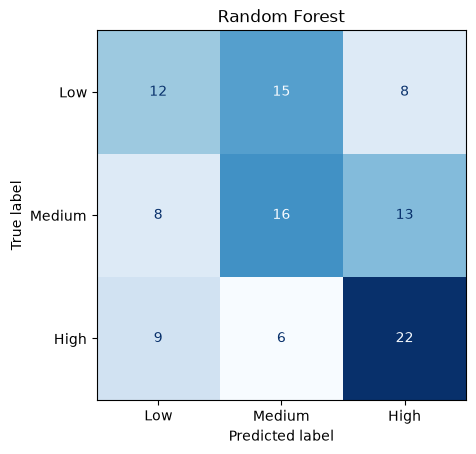


Training: CART
              precision    recall  f1-score   support

         Low      0.273     0.171     0.211        35
      Medium      0.341     0.405     0.370        37
        High      0.372     0.432     0.400        37

    accuracy                          0.339       109
   macro avg      0.329     0.336     0.327       109
weighted avg      0.330     0.339     0.329       109



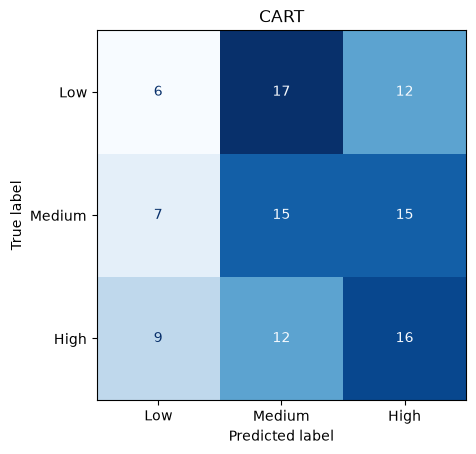


Training: Gradient Boosting


              precision    recall  f1-score   support

         Low      0.391     0.257     0.310        35
      Medium      0.370     0.459     0.410        37
        High      0.575     0.622     0.597        37

    accuracy                          0.450       109
   macro avg      0.445     0.446     0.439       109
weighted avg      0.446     0.450     0.441       109



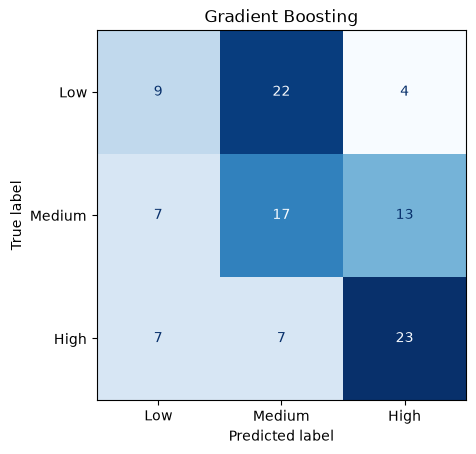


Training: SVM


              precision    recall  f1-score   support

         Low      0.386     0.486     0.430        35
      Medium      0.231     0.162     0.190        37
        High      0.462     0.486     0.474        37

    accuracy                          0.376       109
   macro avg      0.360     0.378     0.365       109
weighted avg      0.359     0.376     0.364       109



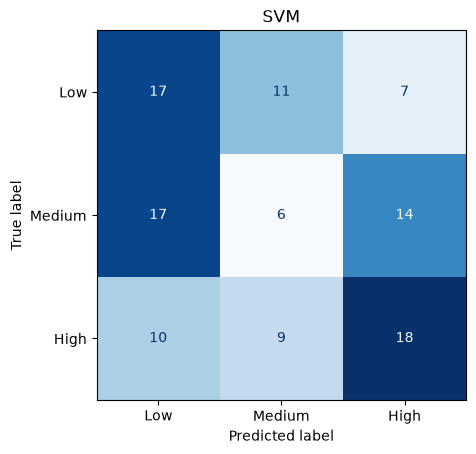

,Model,Accuracy,Balanced accuracy,Macro F1
0,Random Forest,0.458716,0.456628,0.452477
1,Gradient Boosting,0.449541,0.446075,0.439129
2,SVM,0.376147,0.378121,0.364847
3,CART,0.339450,0.336422,0.326966


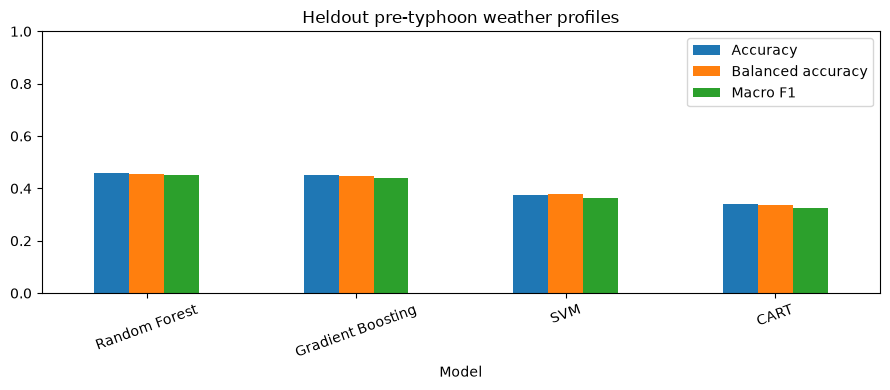

In [7]:
comparison = []
trained_models = {}
metadata = [c for c in ["date", "intl_id", "landfall_event_id", "storm_name", "days_before_landfall", "risk"] if c in test_df]
all_predictions = test_df[metadata].copy()
CLASS_ORDER = ["Low", "Medium", "High"]
for name, estimator in models.items():
    print(f"\nTraining: {name}")
    classifier = Pipeline([("preprocessor", clone(preprocessor)), ("model", estimator)])
    classifier.fit(X_train, y_train)
    predicted = classifier.predict(X_test)
    trained_models[name] = classifier
    comparison.append({"Model": name, "Accuracy": accuracy_score(y_test, predicted),
                       "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
                       "Macro F1": f1_score(y_test, predicted, labels=CLASS_ORDER, average="macro", zero_division=0)})
    print(classification_report(y_test, predicted, labels=CLASS_ORDER, digits=3, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=CLASS_ORDER, cmap="Blues", colorbar=False)
    plt.title(name)
    filename = name.lower().replace(" ", "_")
    plt.savefig(LOG_DIR / f"{filename}_confusion.png", dpi=120, bbox_inches="tight")
    plt.show()
    joblib.dump(classifier, OUTPUT_DIR / f"{filename}_model.joblib")
    all_predictions[name] = predicted

comparison = pd.DataFrame(comparison).sort_values("Balanced accuracy", ascending=False).reset_index(drop=True)
display(comparison)
comparison.set_index("Model")[["Accuracy", "Balanced accuracy", "Macro F1"]].plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title("Heldout pre-typhoon weather profiles")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(LOG_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


## 8. Predict from weather conditions
Set `PREDICTION_FILE` in the settings cell to your weather CSV, or use the heldout example below. The file needs the selected weather columns only; dates/town names can be retained as display metadata. Class probabilities describe the three profiles, not typhoon occurrence probability.

In [8]:
def predict_weather(weather_rows, model_name=MODEL_TO_VIEW):
    if model_name not in trained_models:
        raise ValueError(f"Choose one of {list(trained_models)}.")
    missing = set(FEATURES) - set(weather_rows.columns)
    if missing:
        raise ValueError(f"Prediction input lacks weather attributes: {sorted(missing)}")
    inputs = weather_rows[FEATURES].apply(pd.to_numeric, errors="raise")
    if inputs.empty or np.isinf(inputs.to_numpy()).any() or inputs.isna().all(axis=1).any():
        raise ValueError("Prediction requires nonempty, finite weather observations.")
    classifier = trained_models[model_name]
    keep = [c for c in ["date", "prefecture", "town", "intl_id", "landfall_event_id"] if c in weather_rows]
    result = weather_rows[keep].copy().reset_index(drop=True)
    result["matched_weather_profile"] = classifier.predict(inputs)
    probabilities = classifier.predict_proba(inputs)
    for i, label in enumerate(classifier.classes_):
        result[f"profile_probability_{label.lower()}"] = probabilities[:, i]
    return result

if PREDICTION_FILE is None:
    if not 0 <= ROW_TO_VIEW < len(test_df):
        raise IndexError("ROW_TO_VIEW is outside the heldout set.")
    prediction_weather = test_df.iloc[[ROW_TO_VIEW]].copy()
    print("Actual event profile:", prediction_weather.risk.iloc[0])
else:
    prediction_weather = pd.read_csv(PREDICTION_FILE, encoding="utf-8-sig")
weather_predictions = predict_weather(prediction_weather)
display(weather_predictions.head(10))
weather_predictions.to_csv(OUTPUT_DIR / "weather_profile_predictions.csv", index=False, encoding="utf-8-sig")


Actual event profile: Low


,date,intl_id,landfall_event_id,matched_weather_profile,profile_probability_high,profile_probability_low,profile_probability_medium
0,2000-09-09,14,0014_2000091210,Medium,0.233202,0.230472,0.536326


## 9. See similar historical weather
This table shows the closest **training** weather records to the first prediction row, using normalized weather-feature distance. Coordinates and prefectures do not participate in this match.

In [9]:
matcher_preprocessor = trained_models[MODEL_TO_VIEW].named_steps["preprocessor"]
reference_weather = matcher_preprocessor.transform(X_train)
query_weather = matcher_preprocessor.transform(prediction_weather[FEATURES].apply(pd.to_numeric, errors="raise").iloc[[0]])
matcher = NearestNeighbors(n_neighbors=min(5, len(train_df))).fit(reference_weather)
distances, indices = matcher.kneighbors(query_weather)
columns = [c for c in ["date", "storm_name", "landfall_event_id", "days_before_landfall", "risk"] if c in train_df]
weather_matches = train_df.iloc[indices[0]][columns].copy()
weather_matches.insert(0, "weather_distance", distances[0])
display(weather_matches)
weather_matches.to_csv(OUTPUT_DIR / "similar_historical_weather.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")


,weather_distance,date,storm_name,landfall_event_id,days_before_landfall,risk
21,1.720266,2001-09-08,DANAS,0115_2001091100,3,Low
22,2.368840,2001-09-09,DANAS,0115_2001091100,2,Medium
58,2.480725,2002-08-27,RUSA,0215_2002082912,2,Medium
120,2.511041,2004-07-28,NAMTHEUN,0410_2004073107,3,Low
121,2.511041,2004-07-28,NAMTHEUN,0410_2004073112,3,Low


## 10. Save comparison and experiment records

In [10]:
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
all_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
train_df.to_csv(OUTPUT_DIR / "training_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
test_df.to_csv(OUTPUT_DIR / "testing_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
config = {"features": FEATURES, "classes": CLASS_ORDER, "model_parameters": MODEL_PARAMS, "seed": SEED,
          "input": str(INPUT_FILE), "date_filter": [START_DATE, END_DATE], "pre_landfall_days": [3, 2, 1],
          "label_definition": {"Low": "Day -3", "Medium": "Day -2", "High": "Day -1"},
          "test_storms": sorted(test_df.intl_id.astype(str).unique().tolist()),
          "input_contract": "raw weather only; circular wind transform included in saved pipeline",
          "interpretation": "Similarity to pre-landfall weather, not probability of typhoon occurrence."}
for folder in [OUTPUT_DIR, LOG_DIR]:
    (folder / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
comparison.to_csv(LOG_DIR / "model_comparison.csv", index=False)
print("Saved models and prediction tables:", OUTPUT_DIR)
print("Saved experiment logs:", LOG_DIR)
display(all_predictions.head(10))


Saved models and prediction tables: /workspace/Project-Innovation/Typhoon/training/trained_models/risk/weather_only_v1
Saved experiment logs: /workspace/Project-Innovation/Typhoon/training/experiment_logs/risk/weather_only_v1


,date,intl_id,landfall_event_id,storm_name,days_before_landfall,risk,Random Forest,CART,Gradient Boosting,SVM
0,2000-09-09,14,0014_2000091210,SAOMAI,3,Low,Medium,Medium,Medium,Medium
1,2000-09-10,14,0014_2000091210,SAOMAI,2,Medium,Low,Low,Medium,Low
2,2000-09-11,14,0014_2000091210,SAOMAI,1,High,Medium,Low,Medium,Low
78,2003-06-14,306,0306_2003061720,SOUDELOR,3,Low,Low,Low,Low,Low
79,2003-06-15,306,0306_2003061720,SOUDELOR,2,Medium,Low,High,Low,Low
80,2003-06-16,306,0306_2003061720,SOUDELOR,1,High,Low,Medium,Low,Low
81,2003-06-16,306,0306_2003061904,SOUDELOR,3,Low,Low,Medium,Low,Low
82,2003-06-17,306,0306_2003061904,SOUDELOR,2,Medium,High,High,High,High
83,2003-06-18,306,0306_2003061904,SOUDELOR,1,High,High,High,High,High
105,2003-09-16,315,0315_2003091908,CHOI-WAN,3,Low,Low,High,Low,Low
